Plotting DLC data

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.cm as get_cmap
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
import copy
from scipy.ndimage import gaussian_filter1d
from datetime import datetime
import pickle
import seaborn as sns
from scipy import stats
from scipy.interpolate import interp1d

In [2]:
runMac = 'yes'
date_string = 250205 # if running pickle file, latest is 250124 has likelihood 0.9 cutoff. 250123 has 0.8 cutoff
# date_string = 'likelihood'
saveit = True # save figures

# session = 'Syed3_noNP'
# session = 'Syed2'
# session = 'GNG_free_delay_noNP'
session = 'GNG_free_delay'

In [3]:
if runMac == 'yes':
    main_path = Path(r'/Volumes/VS03-NandB-1/Eugenia/FSCV_Rat_Striatum_GoNogo/Data_analysis/R1_4/DLC')
    path = Path(main_path) / session / 'DLC_transformed'
    path_trigger = Path(main_path) / session / 'Trigger_Info_files'
    
    # For generating figures
    up_fig_dir = Path(main_path) / session / 'Figures' 
    fig_dir = Path(up_fig_dir) / datetime.now().strftime("%y%m%d")
    
    if not os.path.exists(fig_dir):
        os.makedirs(fig_dir)

In [4]:
# ------------------------------------------------
#              Load pickle file!!
# ------------------------------------------------  
filename = f"{date_string}_filt_df.pkl"
file_path = Path(up_fig_dir) / filename
# file_path = Path(r"/Users/eugeniapoh/Documents/Python/DLC/GNG_free_delay_250204_filt_df.pkl")
# Load the filtered DataFrame (done by whole recording) from the pickle file
all_filtered_Dataframe = pd.read_pickle(file_path)

merged_filtered_df = pd.concat(all_filtered_Dataframe, ignore_index=False)

In [5]:
# Open transformed DLC coordinates
files = list(path.glob('*.h5')) # transformed DLC coordinates

# Open trigger files
files_trigger = list(path_trigger.glob('*.csv'))

DLCscorer = 'DLC_resnet50_BehSyl projectDec22shuffle1_100000'
# Get the animal IDs
animals = [file.stem for file in files]
animals = [name.replace('_tform_coords', '') for name in animals]

animal_dict = {}
# Iterate through the files to fill the dictionary 
for file in files:
    file_name = file.name  # Get the file name
    animal = file_name.split('_')[0] # Get the ID by extracting everything before the first _
    # Store the animal as the key and the file name as the value in the dictionary
    animal_dict[animal] = file

filenames_trigger = []
for file_trigger in files_trigger:
    filenames_trigger.append(file_trigger.name)
# Combining the DLC and trigger files for each animal to use as a key later
df_paths = pd.DataFrame(list(animal_dict.items()), columns=['Animal', 'path_DLC'])

# Create an empty column 'path_trigger' in path_df
df_paths['path_trigger'] = ''

# Standardize case and strip whitespaces for matching
df_paths['Animal'] = df_paths['Animal']

 # Iterate over each file path in files_trigger
for file in files_trigger:
    animal_id = file.stem.split('_')[0]
    df_paths.loc[df_paths['Animal'] == animal_id, 'path_trigger'] = str(file)

# to strip all the empties
df_paths = df_paths[df_paths['path_trigger'].notna() & (df_paths['path_trigger'].str.strip() != '')]
df_paths = df_paths.reset_index(drop=True)
animals = df_paths['Animal']

In [6]:
# Test that the files are loading correctly

testdf = pd.read_hdf(files[0])

testdf = testdf[1400:1800]
bodyparts=testdf.columns.get_level_values(1)[::3] #read out the header to get body part names!
print(bodyparts)
bodyparts2plot=bodyparts #you could also take a subset, i.e. =['snout']
scorer = testdf.columns.get_level_values(0)[0]  # Read out the header to get the scorer name!


Index(['snout', 'neck', 'back1', 'back2', 'back3', 'back4', 'tailbase',
       'right paw', 'left paw'],
      dtype='object', name='bodyparts')


In [7]:
def get_cmap(n, name='viridis'):
    return plt.get_cmap(name, n)

def readDLCfiles(df_paths, animal='', path_DLC='path_DLC', path_trigger='path_trigger',):
    try:
        # Get the paths
        selected_pathDLC = df_paths.loc[df_paths['Animal'] == animal, path_DLC].values[0]
        selected_pathtrigger = df_paths.loc[df_paths['Animal'] == animal, path_trigger].values[0]

        df_DLC = pd.read_hdf(selected_pathDLC)
        df_trigger = pd.read_csv(selected_pathtrigger)
    except (IndexError, FileNotFoundError, KeyError) as e:
        print(f"Skipping animal {animal} due to missing data: {e}")

    return df_DLC, df_trigger

# ------------------------      PLOTTING      ------------------------                     
def PlotBodyParts(ax, x_values, y_values, color, alphavalue=.2):
    ''' To plot the bodyparts '''
    midpoint = int(len(x_values)/2)
    # if ax is None:
    #     ax[0].plot(x_values, y_values, color=color, alpha=alphavalue)        
    #     # Draw a star at the start of the trajectory
    #     ax[0].scatter(x_values[0], y_values[0], color=color, marker='*', s=100)
    #     ax[0].scatter(x_values[midpoint], y_values[midpoint], color=color, marker='+', s=100)    
    # else:
    ax.plot(x_values, y_values, color=color, alpha=alphavalue)        
    # Draw a star at the start of the trajectory
    ax.scatter(x_values[0], y_values[0], color=color, marker='*', s=100)
    ax.scatter(x_values[-1], y_values[-1], color=color, marker='x', s=100)    
    

def getSpeedy(coordinates):   
    # Calculate the differences between consecutive points
    diffs = np.diff(coordinates, axis=0)
    
    # Use numpy's efficient vectorized norm to calculate distances
    distances = np.linalg.norm(diffs, axis=1)

    # Time array based on 29.97 FPS
    time = np.arange(len(distances)+1) / 29.97
    # time = time[1:]

    speed = distances / (1/29.97)
    speed = np.insert(speed, 0,0)

    return time, speed

def PlottingTrajSpeed(Dataframe, bodyparts2plot, animal='', alphavalue=.2, colormap='jet', speedbp='', StimCategory='', PresentationNumber=1, title =''):
    ''' Plots the coordinates as linked line and get the speedbp speed. '''
    colors = get_cmap(len(bodyparts2plot), name=colormap)
    scorer = Dataframe.columns.get_level_values(0)[0]  # Read out the header to get the scorer name!
    
    bodypart_coords = {}
    
    fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))

    # Run this for the raw values
    for bp in bodyparts2plot:
        bodypart_coords[bp] = np.vstack((Dataframe[scorer][bp]['x'].values, Dataframe[scorer][bp]['y'].values)).T
        color = colors(bodyparts2plot.get_loc(bp))

        x_values = Dataframe[scorer][bp]['x'].values
        y_values = Dataframe[scorer][bp]['y'].values        
                
        PlotBodyParts(ax, x_values, y_values, color, alphavalue=alphavalue)

        ax[0].invert_yaxis()  
        ax[0].set_xlim(-20,35)
        ax[0].set_ylim(-20,35)

        if title == '':
            if not StimCategory:
                ax[0].set_title(f'{animal} trajectory')
            else:
                ax[0].set_title(f'{animal}: #{PresentationNumber} {StimCategory} trajectory')

        # if manually defining title names
        else:
            ax[0].set_title(f'{title} trajectory', fontsize = 'small')

        ax[0].set_xlabel('cm', labelpad=0.1)
        ax[0].set_ylabel('cm', labelpad=0.1)
        rect = patches.Rectangle((0, 0), 26.9, 31.8, linewidth=2, edgecolor='r', facecolor='none')
        ax[0].add_patch(rect)
        
        if speedbp == '':
        # Get bodyparts speed and plot them
            time, bp_speed = getSpeedy(bodypart_coords[bp])
            ax[1].plot(time, bp_speed, label=bp, color=color)  # Plot each body part's filtered speed
            ax[1].set_ylabel('speed [cm/s]', labelpad=0.1)
            ax[1].set_xlabel('time [s]', labelpad=0.1)
            ax[1].vlines(x=10, ymin=-3, ymax=max(bp_speed), linestyles=':', colors='k')

            if title == '':
                ax[1].set_title(f'{animal}: speed of all body parts')                           
            else:
                ax[1].set_title(f'{title}: speed of all body parts', fontsize = 'small') # if manually defining title names 

            textstr = '\n'.join((
            r'$\mathrm{frame1}=%.0f$' % (Dataframe.index[0], ),
            r'$\mathrm{frame-1}=%.0f$' % (Dataframe.index[-1], )))
                
            # these are matplotlib.patch.Patch properties
            props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
            
            ax[1].text(0.05, 0.95, textstr, transform=ax[1].transAxes, fontsize=10,
            verticalalignment='top', bbox=props)

    if speedbp != '':
        time, bp_speed = getSpeedy(bodypart_coords[speedbp])
        ax[1].plot(time, bp_speed, label=bp, color=color)  # Plot each body part's filtered speed
        ax[1].set_ylabel('speed [cm/s]', labelpad=0.1)
        ax[1].set_xlabel('time [s]', labelpad=0.1)
        ax[1].vlines(x=10, ymin=-3, ymax=max(bp_speed), linestyles=':', colors='k')

        if title == '':
            ax[1].set_title(f'{animal}: {speedbp} speed')
        else: 
            ax[1].set_title(f'{title} {speedbp} speed', fontsize = 'small')    # if manually defining title names

        textstr = '\n'.join((
        r'$\mathrm{first}=%.0f$' % (Dataframe.index[0], ),
        r'$\mathrm{last}=%.0f$' % (Dataframe.index[-1], )))
            
        # these are matplotlib.patch.Patch properties
        props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
        
        ax[1].text(0.05, 0.95, textstr, transform=ax[1].transAxes, fontsize=10,
        verticalalignment='top', bbox=props)

def save_figure(fig_dir, name, figure, folder_name='', saving = False):
    '''    Saves a given figure with a specific naming convention based on the parameters provided. '''
    if saving == True:
        today_date = datetime.now().strftime('%y%m%d')  # Format: DDMMYY
        if folder_name == '':
            fig_folder = os.path.join(fig_dir, today_date) # Create the folder if it doesn't exist
            os.makedirs(fig_folder, exist_ok=True)

            # Full path for saving the figure
            fig_path = os.path.join(fig_folder, name)

            # Save the figure
            figure.savefig(fig_path)
        else:
            fig_folder = os.path.join(fig_dir, today_date) # Create the folder if it doesn't exist
            os.makedirs(fig_folder, exist_ok=True)
            sub_folder = os.path.join(fig_folder, folder_name) # Create the folder if it doesn't exist
            os.makedirs(sub_folder, exist_ok=True)

            # Full path for saving the figure
            fig_path = os.path.join(sub_folder, name)

            # Save the figure
            figure.savefig(fig_path)


In [8]:
df_DLC = {}
df_trigger = {}

selected_triggers = 'path_trigger'

for index, row in df_paths.iterrows():
    path_trigger = row[selected_triggers]
    animal = animals[index]
    # animal = '191101.02.03'
    
    if not path_trigger:  # Check if 'path_trigger' is empty
        print(f"Skipping for {animal} as there is no analysed video")
        continue
    else:
        # Grab all the file information
        df_DLC[animal], df_trigger[animal] = readDLCfiles(df_paths, animal=animal)
        
    alignments = df_trigger[animal]['Centering'].unique()
    conditions = df_trigger[animal]['TrialType'].unique()


In [9]:
def getDLCwindow(df_DLC, df_trigger, pre_stimtime=10, post_stimtime=10, TrialType=''):
    """Get the trajectories for each animal, for each trial type
    
    Parameters:
    - df_DLC: DataFrame containing DLC data.
    - df_trigger: DataFrame containing trigger events.
    - pre_stimtime: Time in seconds to include before stimulus.
    - post_stimtime: Time in seconds to include after stimulus.
    - TrialType: Category of stimulus to filter (if any).
    
    Returns:
    - df_DLC: The modified full DLC DataFrame windowed to the entire trial period.
    - df_subset: A subset of df_DLC centered around the stimulus.
    """
    fps = 29.97
    if not TrialType:
        index = df_trigger['VideoFrame'].idxmax()
        # Determine the frame of the last stimulus
        stimtime = int(df_trigger.loc[index, 'VideoFrame'].item())

        start = int(np.floor(stimtime - (pre_stimtime * fps)))
        stop = int(np.ceil(stimtime + (post_stimtime * fps)))
        
        df_subset = df_DLC[start:stop]
            
    else:
        # Get the index to find the trialtype
        index = df_trigger[(df_trigger['TrialType'] == TrialType)].index

        stimtime = int(df_trigger.loc[index, 'VideoFrame'].item())
        start = int(np.floor(stimtime - (pre_stimtime * fps)))
        stop = int(np.ceil(stimtime + (post_stimtime * fps)))

        df_subset = df_DLC[start:stop]

    # get the last trial and add 120s
    whole_stop = int(df_trigger.iloc[-1]['VideoFrame'].item())

    whole_stop = whole_stop + int(120 * fps)
    whole_stop = int(np.ceil(whole_stop))

    df_DLC = df_DLC[:whole_stop]            

    return df_DLC, df_subset

In [10]:
def PlottingCoord(Dataframe, bodyparts2plot='', alphavalue=.2, colormap='jet', ax='', title = ''):
    ''' Plots the coordinates as linked line and get the speedbp speed. '''
    bodyparts=np.unique(Dataframe.columns.get_level_values(1))#read header to get body part names
    colors = get_cmap(len(bodyparts), name=colormap)
    scorer = Dataframe.columns.get_level_values(0)[0]  # Read out the header to get the scorer name!

    bodypart_coords = {}

    if bodyparts2plot == '':
        for idx, bp in enumerate(bodyparts):
            bodypart_coords[bp] = np.vstack((Dataframe[scorer][bp]['x'].values, Dataframe[scorer][bp]['y'].values)).T
            color = colors(idx)
            x_values = Dataframe[scorer][bp]['x'].values
            y_values = Dataframe[scorer][bp]['y'].values        
                    
            PlotBodyParts(ax, x_values, y_values, color, alphavalue=alphavalue)
            
        if title =='':
            ax.set_title('Bodypart Trajectories')
        else:
            ax.set_title(f'{title}')

    elif len(bodyparts2plot) > 1:
        name = ""
        
        for idx, bp in enumerate(bodyparts2plot):
            bodypart_coords[bp] = np.vstack((Dataframe[scorer][bp]['x'].values, Dataframe[scorer][bp]['y'].values)).T
            color = colors(idx)
            x_values = Dataframe[scorer][bp]['x'].values
            y_values = Dataframe[scorer][bp]['y'].values        
            PlotBodyParts(ax, x_values, y_values, color, alphavalue=alphavalue)
            if name:  # If 'name' isn't empty, add an underscore
                name += ", "
            name += bp  # Add the current body part to the string
            
        if title =='':
            ax.set_title(f'{name} Trajectories')
        else:
            ax.set_title(f'{title}')

    else:
        
        bp = bodyparts2plot
        idx = np.where(bodyparts == bodyparts2plot)[0][0]  # Get the first occurrence index

        bodypart_coords = np.vstack((Dataframe[scorer][bp]['x'].values, Dataframe[scorer][bp]['y'].values)).T
        color = colors(idx)

        x_values = Dataframe[scorer][bp]['x'].values
        y_values = Dataframe[scorer][bp]['y'].values        
                
        PlotBodyParts(ax, x_values, y_values, color, alphavalue=alphavalue)
        if title =='':
            ax.set_title(f'{bp} Trajectories')
        else:
            ax.set_title(f'{title}')

    ax.set_xlabel('cm', labelpad=0.1)
    ax.set_ylabel('cm', labelpad=0.1)
    rect = patches.Rectangle((0, 0), 26.9, 31.8, linewidth=2, edgecolor='r', facecolor='none')
    ax.add_patch(rect)

    # ax.invert_yaxis()  
    ax.set_xlim(-5,35)
    ax.set_ylim(-5,35)
    
def getOrientationAngle(xy1, xy2):
    ''' Get the orientation of the rat relative to the speaker. Uses head and neck coordinates '''   
    x_wall = 0 # x coord of wall with panel of interest

    y_range = [7, 24]
    y_center = [x_wall, (max(y_range)+min(y_range))/2]

    # Calculate orientation angle
    big_angle = np.arctan2(xy2[:, 1] - xy1[:, 1], xy2[:, 0] - xy1[:, 0])  # in radians

    # Convert big_angle to degrees and normalize to 0-360 range
    big_angle_deg = np.degrees(big_angle) % 360  # Convert to degrees and wrap to [0, 360)

    # Calculate the y position where line intersects the x_wall
    x1_wall = x_wall - xy1[:, 0]
    y_crossing = xy1[:, 1] + np.tan(big_angle) * x1_wall  # crossing point along y-axis

    # Check if y_crossing falls within y_range
    x_crossing_in_range = (y_crossing >= y_range[0]) & (y_crossing <= y_range[1])
    condition = xy1[:,0]>xy2[:,0]
    x_crossing_in_range = np.where(condition & x_crossing_in_range, False, x_crossing_in_range)
    
    # Small angle for further use if needed, corrected for y_center
    small_angle = np.arctan2(x1_wall, y_crossing - y_center[1])  # in radians
    small_angle = np.degrees(small_angle) % 360  # Shift by 90 degrees for plotting, convert to degrees and wrap to [0, 360)

    return x_crossing_in_range, small_angle, big_angle_deg

def getFrameWindows(stimtime='', pre_stimtime=5, post_stimtime=5, fps = 29.97):
    if stimtime is None or stimtime == '' or np.isnan(stimtime):
        print('missing trial')
        return None, None

    else:
        start = int(np.floor(stimtime - (pre_stimtime * fps)))
        stop = int(np.floor(stimtime + (post_stimtime * fps)))
        return start, stop

missing trial


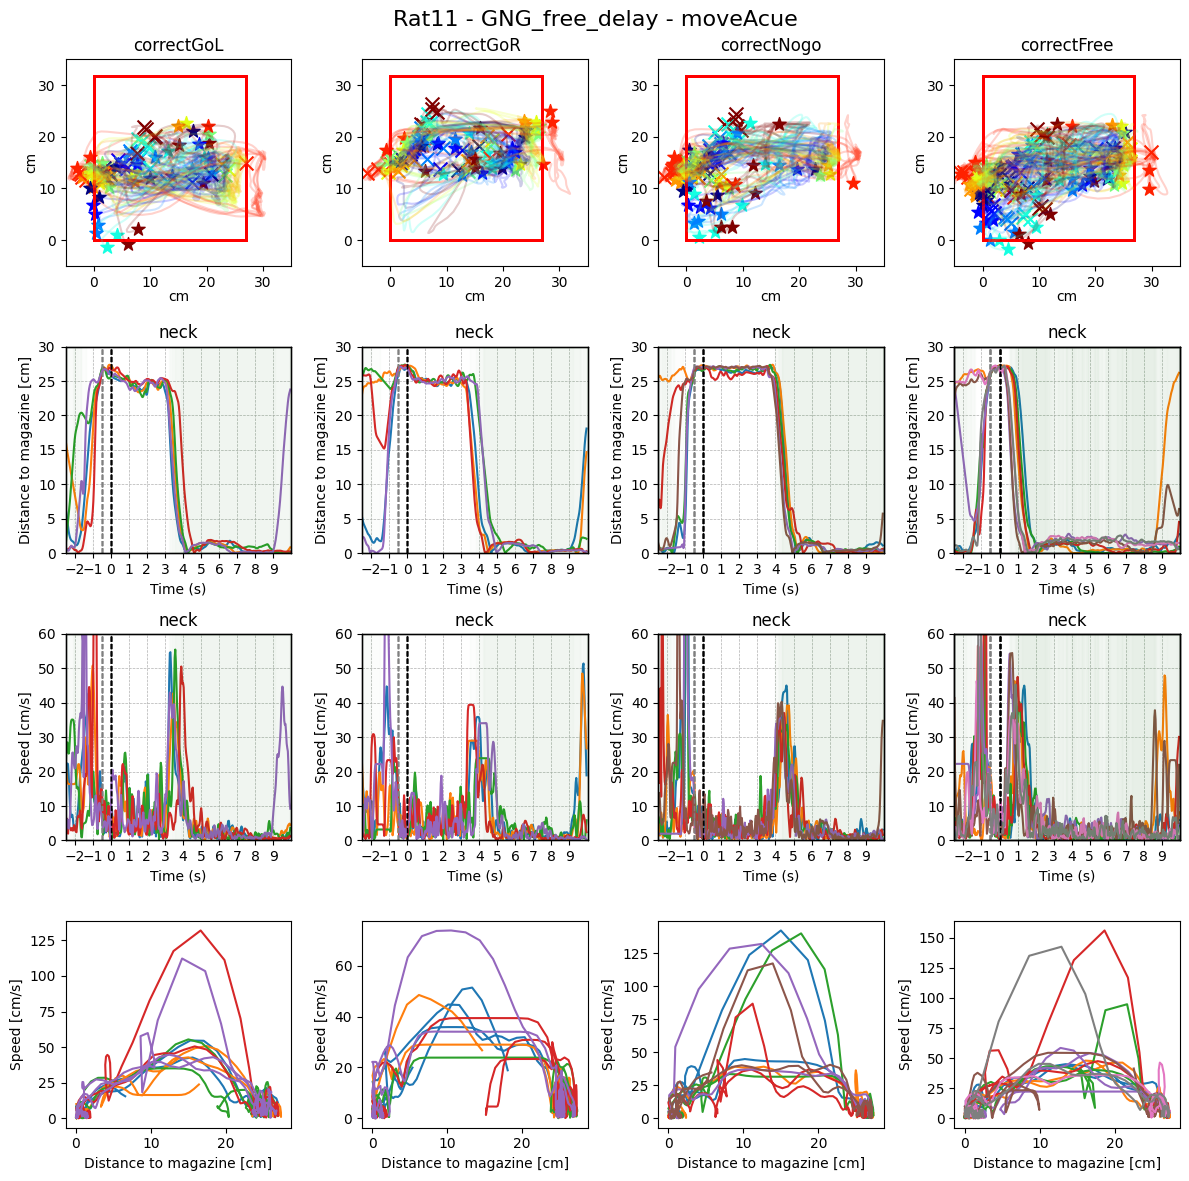

In [86]:
alignment = alignments[0]
bodypart2plot = 'neck'
scorer = 'DLC_resnet50_BehSyl projectDec22shuffle1_100000'
fps = 29.97
pre_stimtime = 2.5
post_stimtime = 10
nrows = 4
saveit = False

for animal in animals:
    animal = 'Rat11'
    fig, axes = plt.subplots(nrows=nrows, ncols=len(conditions), figsize=(3 * len(conditions), nrows*3))
    for condition_idx, condition in enumerate(conditions):
        # get the subset based on alignment = 'centering', and condition = 'trialtype' 
        subset = df_trigger[animal][(df_trigger[animal]['Centering']==alignment) &
                                    (df_trigger[animal]['TrialType']==condition)].reset_index(drop=True)
        ax0 = axes[0,condition_idx] if len(condition) > 1 else axes[0]  # Handle single subplot case
        ax1 = axes[1, condition_idx] if len(condition) > 1 else axes[1]  
        ax2 = axes[2, condition_idx] if len(condition) > 1 else axes[2]  
        ax3 = axes[3, condition_idx] if len(condition) > 1 else axes[3]

        fig.suptitle(f"{animal} - {session} - {alignment}", fontsize=16)  # Title for the figure

        for idx in range(len(subset)):
            stimtime = subset['VideoFrame'][idx]
            start, stop = getFrameWindows(
                stimtime=stimtime, 
                pre_stimtime=pre_stimtime, 
                post_stimtime=post_stimtime)
            
            if start is not None and stop is not None:
                try:
                    # Plot the data for this trial in the current subplot
                    animal_data = all_filtered_Dataframe[animal][start:stop]
                    scorer_data = animal_data[scorer]
                    bodypart_data = scorer_data[bodypart2plot]

                    distance2mag_data = bodypart_data['distance']
                    speed_data = bodypart_data['speed']
                    acceleration_data = bodypart_data['acceleration']
                    orientation_data = bodypart_data['orientation']
                    # acceleration_data = np.gradient(bodypart_data['speed'], 1 / fps) # calculate accelerations for now, since it's not in the df

                    # To get orientation -> are they looking at the magazine?
                    # snout = np.array([scorer_data['snout']['x'], scorer_data['snout']['y']]).T
                    # neck = np.array([scorer_data['neck']['x'], scorer_data['neck']['y']]).T

                    # x_cross_range, _, _ = getOrientationAngle(snout, neck)

                    # trial_data = all_filtered_Dataframe[animal][start:stop][scorer][bodypart2plot]['speed']                
                    time = np.arange(-pre_stimtime, len(speed_data) / fps - pre_stimtime, 1 / fps)

                    # To Plot:
                    # ------------------------------
                    #       Trajectories in box
                    # ------------------------------                     
                    PlottingCoord(animal_data, 
                                bodyparts2plot='', 
                                alphavalue=.2, 
                                colormap='jet', 
                                ax = ax0,
                                title = condition)

                    # ------------------------------
                    #      Distance to magazine
                    # ------------------------------ 
                    ax1.plot(time, np.abs(distance2mag_data))
                    ax1.set_ylabel("Distance to magazine [cm]")
                    ax1.set_ylim(0, 30) # Set fixed y-axis limits (0–60 cm/s)
                    ax1.title.set_text(bodypart2plot)

                    # ------------------------------
                    #           Speed
                    # ------------------------------ 
                    ax2.plot(time, speed_data)  # Optionally add labels
                    ax2.set_ylabel("Speed [cm/s]")
                    ax2.set_ylim(0, 60) # Set fixed y-axis limits (0–60 cm/s)
                    ax2.title.set_text(bodypart2plot)

                    
                    # ------------------------------------------------------------
                    #           Acceleration or [Speed vs Distance]
                    # ------------------------------------------------------------
                    # ax3.plot(time, acceleration_data)
                    # ax3.set_ylabel("Acceleration [cm s-2]")
                    # ax3.title.set_text(bodypart2plot)
                    ax3.plot(np.abs(distance2mag_data), speed_data)
                    ax3.set_ylabel("Speed [cm/s]")
                    ax3.set_xlabel("Distance to magazine [cm]")
            
                    for ax in [ax1, ax2]: # removed ax3
                        ax.axvline(x=-0.5, color="gray", linestyle="--", lw=1, label="Head Entry")
                        ax.axvline(x=0, color="black", linestyle="--", lw=1, label="Stimulus Onset")
                        
                        # Set fixed x-axis limits (based on pre_stimtime and post_stimtime)
                        ax.set_xlim(-pre_stimtime, post_stimtime)
                        ax.set_xticks(np.arange(-pre_stimtime+0.5, post_stimtime, 1))  # 1-second intervals
                        ax.set_xlabel("Time (s)")        
                        
                        # To shade the values
                        ax99 = ax.twinx()
                        ax99.fill_between(
                            time, # x-axis
                            0, 
                            1, 
                            where=orientation_data, 
                            color='green', 
                            alpha=0.01, 
                            label='x_cross_in_range'
                        )
                        # ax99.tick_params(axis='y', labelcolor='green', right=False)
                        ax99.set_yticks([])  # Removes tick marks
                        ax99.set_yticklabels([])  # Removes tick labels
                        ax99.yaxis.set_visible(False)  # Hides the entire y-axis
                        ax99.set_ylim(0,1)

                        ax.grid(True, which='both', linestyle='--', linewidth=0.5)   
                    
                except Exception:
                    continue
                # ------------------------------
                #     Plot max speed traces
                # ------------------------------ 

                # Find the max value
                # max_value = speed_data.max()

                # if max_value > 60:
                #     max_index = speed_data.idxmax()
                #     # timepoint = max_index/29.97/60
                #     time_in_seconds = max_index / 29.97  # Convert to seconds
                #     minutes = int(time_in_seconds // 60)  # Integer minutes
                #     seconds = time_in_seconds % 60  # Remaining seconds
                    
                #     # timepoint = time[max_index]
                #     print(f"{animal} {condition} Trial {idx}: max value {max_value} at {minutes} min {seconds:.0f} sec")
                #     # Reset index of trial_data
                #     speed_data = speed_data.reset_index(drop=True)

                #     max_index = speed_data.idxmax()

                #     ax.plot(time, speed_data)  # Optionally add labels
                #     ax.title.set_text(condition)

                #     ax.axvline(x=0, color="gray", linestyle="--", label="Head Entry")
                #     ax.axvline(x=0.5, color="black", linestyle="--", label="Stimulus Onset")

                #     PlottingCoord(animal_data, bodyparts2plot='', alphavalue=.2, colormap='jet', ax = ax2)
        fig.tight_layout()
        
    if saveit == True:
        fig_name = animal + '_' + alignment + '_' + bodypart2plot + 'from-2sto7s' + '.png'
        fig_path = os.path.join(fig_dir, fig_name)
        plt.savefig(fig_path)
    
    break


In [ ]:
bodypart2plot = 'neck'
pre_stimtime = 0 # Start at 0 for finding corresponding DA
post_stimtime = 20
min_block_length = 3 # number of consecutive frames for orientation


DLC_outputs = []

for animal in animals: 

    for condition_idx, condition in enumerate(conditions):
        subset = df_trigger[animal][(df_trigger[animal]['Centering']==alignment) &
                                    (df_trigger[animal]['TrialType']==condition)].reset_index(drop=True)
        
        # DA_columns = [col for col in subset.columns if col.startswith("DA")] # select the columns that start with DA
        # DA_array = subset[DA_columns].to_numpy()

        for idx in range(len(subset)):
            stimtime = subset['VideoFrame'][idx]
            # DA_data = DA_array[idx,:]

            start, stop = getFrameWindows(
                stimtime=stimtime, 
                pre_stimtime=pre_stimtime, 
                post_stimtime=post_stimtime)
            
            if start is not None and stop is not None:
                animal_data = all_filtered_Dataframe[animal][start:stop].reset_index(drop=True) # drop the index to find it later
                scorer_data = animal_data[scorer]
                bodypart_data = scorer_data[bodypart2plot]

                distance2mag_data = bodypart_data['distance']
                speed_data = bodypart_data['speed']
                acceleration_data = bodypart_data['acceleration']
                orientation_data = bodypart_data['orientation']

                indices = np.arange(len(orientation_data))

                # Find moments where the rat is oriented
                true_blocks = np.where(orientation_data)[0]

                # Find consecutive sequences of True values
                diff = np.diff(true_blocks)
                split_indices = np.where(diff > 1)[0] + 1  # Find breaks in continuity
                consecutive_blocks = np.split(true_blocks, split_indices)

                # Find the first block where the rat is orienting with at least `min_block_length` frames
                valid_blocks = [block for block in consecutive_blocks if len(block) >= min_block_length]
                try:
                    # if valid_blocks:
                    first_valid_block = valid_blocks[0]  # Take the first valid block
                    block_start_idx = first_valid_block[0]

                    # find the moment that they reach the magazine
                    block_end_idx = (bodypart_data['distance'].abs() < 2).to_numpy().argmax() # gets the first time that distance <2

                    # Get corresponding times
                    block_frames = bodypart_data.index[block_start_idx:block_end_idx + 1]
                    block_times = np.round(block_frames.to_numpy() / fps, 2)
                    block_distance = abs(distance2mag_data.loc[block_start_idx] - distance2mag_data.loc[block_end_idx + 1])
                    block_speed = block_distance * (fps / len(block_frames))
                    
                    first_orient_s = block_frames[0]/fps
                    reach_mag_s = block_frames[-1]/fps

                    print(f"Found for {animal} {condition} {idx+1}")

                    DLC_outputs.append({
                        'subjectID': animal,
                        'condition': condition,
                        'trialno': idx+1,
                        'orient_s': first_orient_s,
                        'mag_reach_s': reach_mag_s,
                        'distance_travelled_cm': block_distance,
                        'speed2mag': block_speed
                    })


                    # print(f'{animal} {condition} Trial {idx+1}: Orientation block found from {block_times[0]} to {block_times[-1]}s')
                    # print(f'  Average speed in block is {round(block_speed,2)} cm/s')
                    # print(f'  Rat oriented at {round(first_orient_s,2)}s')
                except:
                    print(f"Couldn't find a block for {animal} {condition} {idx+1}")


                
                # Find the window where there is a block of True for orientation

                # Find the moment where there is a True from that block (or combine with above in a function)

                # Return the average and max speed in the block where the rat is oriented
    



Found for Rat10 correctGoL 1
Found for Rat10 correctGoL 2
Found for Rat10 correctGoL 3
Found for Rat10 correctGoL 4
missing trial
Found for Rat10 correctGoL 6
Found for Rat10 correctGoL 7
Found for Rat10 correctGoL 8
Found for Rat10 correctGoL 9
Found for Rat10 correctGoL 10
Found for Rat10 correctGoL 11
Found for Rat10 correctGoL 12
Found for Rat10 correctGoL 13
Found for Rat10 correctGoL 14
Found for Rat10 correctGoL 15
Found for Rat10 correctGoL 16
missing trial
Found for Rat10 correctGoL 18
Found for Rat10 correctGoL 19
Found for Rat10 correctGoL 20
Found for Rat10 correctGoL 21
Found for Rat10 correctGoL 22
Found for Rat10 correctGoL 23
Found for Rat10 correctGoL 24
Found for Rat10 correctGoL 25
missing trial
missing trial
missing trial
Found for Rat10 correctGoR 4
Found for Rat10 correctGoR 5
missing trial
Found for Rat10 correctGoR 7
Found for Rat10 correctGoR 8
Found for Rat10 correctGoR 9
Found for Rat10 correctGoR 10
Found for Rat10 correctGoR 11
Found for Rat10 correctGoR 12

In [123]:
DLC_outputs

[{'subjectID': 'Rat10',
  'condition': 'correctGoL',
  'trialno': 1,
  'orient_time': 3.0363697030363697,
  'mag_reach_time': 3.4034034034034035,
  'speed2mag': 26.399011001462828,
  'distance_travelled': 10.57017457516029},
 {'subjectID': 'Rat10',
  'condition': 'correctGoL',
  'trialno': 2,
  'orient_time': 3.7370704037370706,
  'mag_reach_time': 4.170837504170838,
  'speed2mag': 24.779773577704137,
  'distance_travelled': 11.575469806068},
 {'subjectID': 'Rat10',
  'condition': 'correctGoL',
  'trialno': 3,
  'orient_time': 3.4367701034367704,
  'mag_reach_time': 3.9372706039372707,
  'speed2mag': 24.848805903566685,
  'distance_travelled': 13.26596244434658},
 {'subjectID': 'Rat10',
  'condition': 'correctGoL',
  'trialno': 4,
  'orient_time': 3.3700367033700367,
  'mag_reach_time': 3.903903903903904,
  'speed2mag': 26.555255934107386,
  'distance_travelled': 15.063041404064917},
 {'subjectID': 'Rat10',
  'condition': 'correctGoL',
  'trialno': 6,
  'orient_time': 3.403403403403403